# 1. **Project Overview**

# Sleep Health & Lifestyle Analysis
This project explores the relationship between sleep, stress, physical activity, and other health-related factors using a sleep health and lifestyle dataset.

My goal was to understand the data, identify patterns, and explore whether people with similar lifestyle characteristics could be grouped together.

Using Python, I cleaned and prepared the dataset, carried out exploratory data analysis (EDA), created visualizations, examined correlations, and applied K-Means clustering to explore lifestyle patterns.

My approach was to examine the available evidence, look for patterns, and interpret the findings carefully.

Key questions:
- What does the dataset reveal about sleep duration, stress, and physical activity?
- How do selected lifestyle and health variables relate to one another?
- Can K-Means clustering identify groups of individuals with similar sleep and lifestyle characteristics?
- What are the limitations of these findings, and what further analysis could be useful?

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 2. Data Loading and Initial Inspection

In [ ]:
project_dir = Path.cwd()
data_dir = project_dir / "/content/Data"
data_path = data_dir / "/content/Data/Sleep_health_and_lifestyle_dataset_.csv"

# Load the dataset
if data_path.exists():
    df = pd.read_csv(data_path)

df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [ ]:
# Initial Inspection
df.info()
print("\nShape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB

Shape: (374, 13)

Mis

# 3. Data Cleaning and Preparation


In [ ]:
# Make a copy so we can safely modify the data
df_clean = df.copy()

# Standardize whitespace and text in string columns
for col in ["Gender", "BMI Category", "Occupation", "Sleep Disorder"]:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype(str).str.strip()

# Standardize case for selected text columns
df_clean["Gender"] = df_clean["Gender"].str.title()
df_clean["BMI Category"] = df_clean["BMI Category"].str.title()
df_clean["Occupation"] = df_clean["Occupation"].str.title()

# Standardize BMI category labels
df_clean["BMI Category"] = (
    df_clean["BMI Category"]
    .replace({
        "Normal Weight": "Normal"
    })
    .str.strip()
)

# Verify the corrected categories
print("BMI category counts:")
print(df_clean["BMI Category"].value_counts())

print("\nBMI category percentages:")
print(
    (df_clean["BMI Category"].value_counts(normalize=True) * 100)
    .round(1)
)

# Split blood pressure into systolic and diastolic values
if "Blood Pressure" in df_clean.columns:
    bp_split = df_clean["Blood Pressure"].astype(str).str.split("/", expand=True)
    df_clean["Systolic_BP"] = pd.to_numeric(bp_split[0], errors="coerce")
    df_clean["Diastolic_BP"] = pd.to_numeric(bp_split[1], errors="coerce")
    df_clean = df_clean.drop(columns=["Blood Pressure"])

# Standardize Sleep Disorder labels
# Replace "None" with "No Disorder"
df_clean["Sleep Disorder"] = (
    df_clean["Sleep Disorder"]
    .replace(["nan"], "No Disorder")
    .astype(str)
    .str.replace("_", " ", regex=False)
    .str.title()
)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Remove identifier column (it is not useful for analytic modeling)
if "Person ID" in df_clean.columns:
    df_clean = df_clean.drop(columns=["Person ID"])

# Check missing values again
print("Missing values after cleaning:\n", df_clean.isnull().sum())

# Drop rows with any remaining missing values in required columns
required_cols = [
    "Gender", "Age", "Occupation", "Sleep Duration", "Quality of Sleep",
    "Physical Activity Level", "Stress Level", "BMI Category",
    "Heart Rate", "Daily Steps", "Sleep Disorder", "Systolic_BP", "Diastolic_BP"
]

df_clean = df_clean.dropna(subset=required_cols).reset_index(drop=True)

print("\nFinal cleaned dataset shape:", df_clean.shape)
print("\nUnique BMI Categories after standardization:", df_clean["BMI Category"].unique())
df_clean.head()

BMI category counts:
BMI Category
Normal        216
Overweight    148
Obese          10
Name: count, dtype: int64

BMI category percentages:
BMI Category
Normal        57.8
Overweight    39.6
Obese          2.7
Name: proportion, dtype: float64
Missing values after cleaning:
 Gender                     0
Age                        0
Occupation                 0
Sleep Duration             0
Quality of Sleep           0
Physical Activity Level    0
Stress Level               0
BMI Category               0
Heart Rate                 0
Daily Steps                0
Sleep Disorder             0
Systolic_BP                0
Diastolic_BP               0
dtype: int64

Final cleaned dataset shape: (374, 13)

Unique BMI Categories after standardization: ['Overweight' 'Normal' 'Obese']


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,No Disorder,126,83
1,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,No Disorder,125,80
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,No Disorder,125,80
3,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


Before analysing the data, I;
- Inspected the dataset to understand its structure, data types, and missing values.
- Prepared the data for analysis by standardizing text labels, converting blood pressure readings into separate systolic and diastolic columns, and checking for duplicate records.
- Reviewed missing values in the columns needed for the analysis.
These steps helped make the dataset more consistent and suitable for exploration.

During data preparation, I also considered whether each transformation preserved the original meaning of the data. This is important because incorrect category changes or unnecessary removal of records can affect the findings.


# 4. Exploratory Data Analysis (EDA)

In [ ]:
# Summary statistics for numeric columns
df_clean.describe(include="all")

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
count,374,374.000000,374,374.000000,374.000000,374.000000,374.000000,374,374.000000,374.000000,374,374.000000,374.000000
unique,2,NaN,11,NaN,NaN,NaN,NaN,3,NaN,NaN,3,NaN,NaN
top,Male,NaN,Nurse,NaN,NaN,NaN,NaN,Normal,NaN,NaN,No Disorder,NaN,NaN
freq,189,NaN,73,NaN,NaN,NaN,NaN,216,NaN,NaN,219,NaN,NaN
mean,NaN,42.184492,NaN,7.132086,7.312834,59.171123,5.385027,NaN,70.165775,6816.844920,NaN,128.553476,84.649733
std,NaN,8.673133,NaN,0.795657,1.196956,20.830804,1.774526,NaN,4.135676,1617.915679,NaN,7.748118,6.161611
min,NaN,27.000000,NaN,5.800000,4.000000,30.000000,3.000000,NaN,65.000000,3000.000000,NaN,115.000000,75.000000
25%,NaN,35.250000,NaN,6.400000,6.000000,45.000000,4.000000,NaN,68.000000,5600.000000,NaN,125.000000,80.000000
50%,NaN,43.000000,NaN,7.200000,7.000000,60.000000,5.000000,NaN,70.000000,7000.000000,NaN,130.000000,85.000000
75%,NaN,50.000000,NaN,7.800000,8.000000,75.000000,7.000000,NaN,72.000000,8000.000000,NaN,135.000000,90.000000


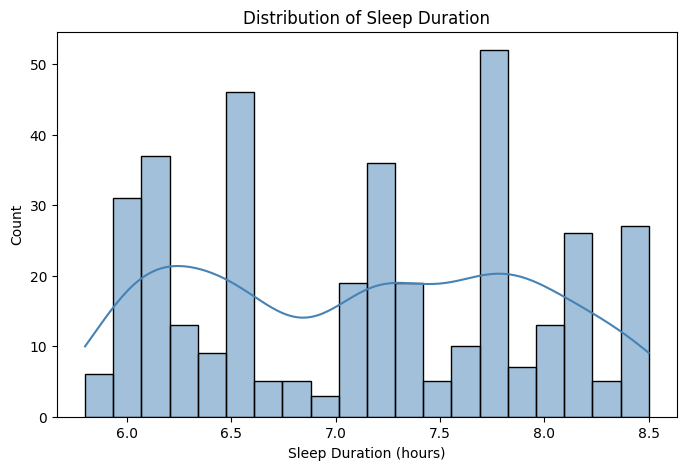

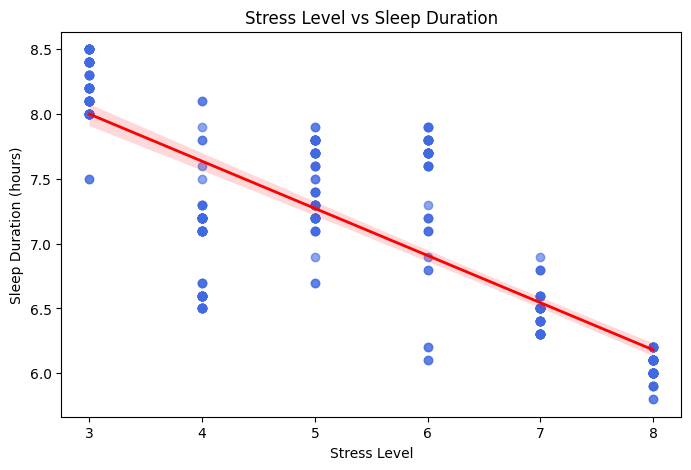

In [ ]:
# Sleep Duration distribution
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["Sleep Duration"], bins=20, kde=True, color="steelblue")
plt.title("Distribution of Sleep Duration")
plt.xlabel("Sleep Duration (hours)")
plt.ylabel("Count")
plt.show()

# Stress vs Sleep Duration
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df_clean,
    x="Stress Level",
    y="Sleep Duration",
    scatter_kws={"alpha": 0.6, "color": "royalblue"},
    line_kws={"color": "red", "linewidth": 2}
)
plt.title("Stress Level vs Sleep Duration")
plt.xlabel("Stress Level")
plt.ylabel("Sleep Duration (hours)")
plt.show()

/tmp/ipykernel_2131/1346587856.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="Gender", ax=axes[0], palette="Set2")
/tmp/ipykernel_2131/1346587856.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="BMI Category", ax=axes[1], palette="Set3")
/tmp/ipykernel_2131/1346587856.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="Sleep Disorder", ax=axes[2], palette="pastel")


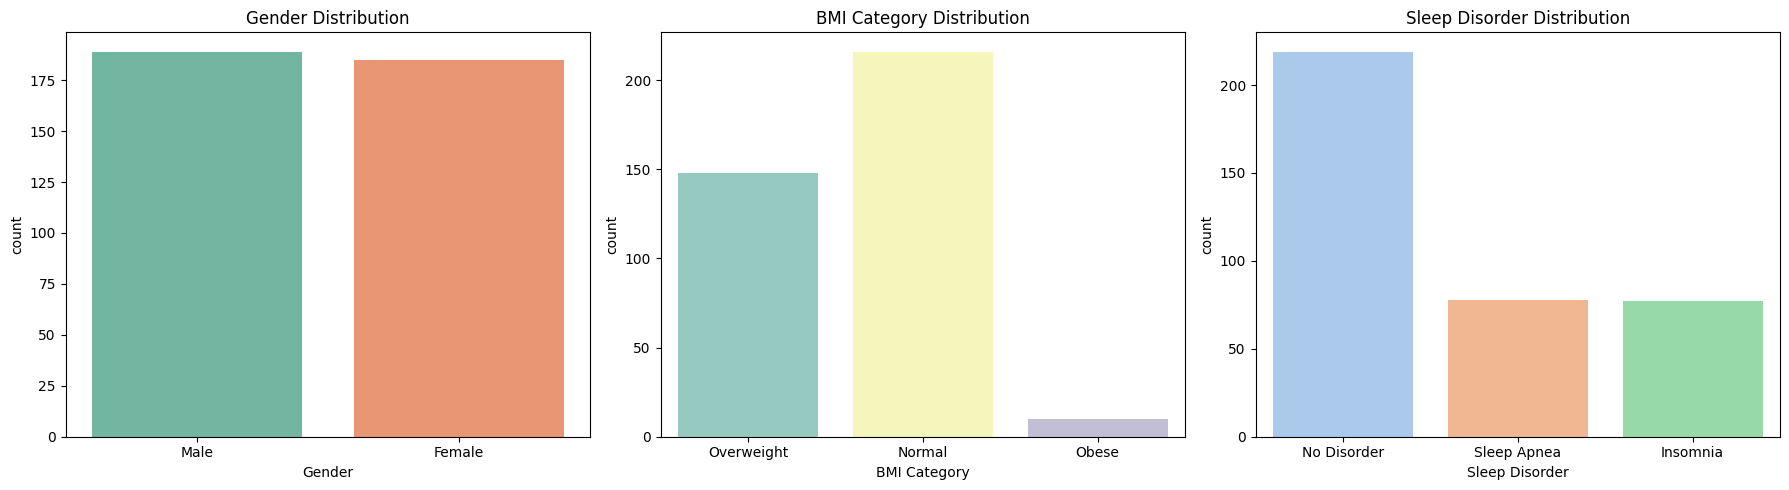

In [ ]:
# Count plots for key categorical variables
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df_clean, x="Gender", ax=axes[0], palette="Set2")
axes[0].set_title("Gender Distribution")

sns.countplot(data=df_clean, x="BMI Category", ax=axes[1], palette="Set3")
axes[1].set_title("BMI Category Distribution")

sns.countplot(data=df_clean, x="Sleep Disorder", ax=axes[2], palette="pastel")
axes[2].set_title("Sleep Disorder Distribution")

plt.tight_layout()
plt.show()

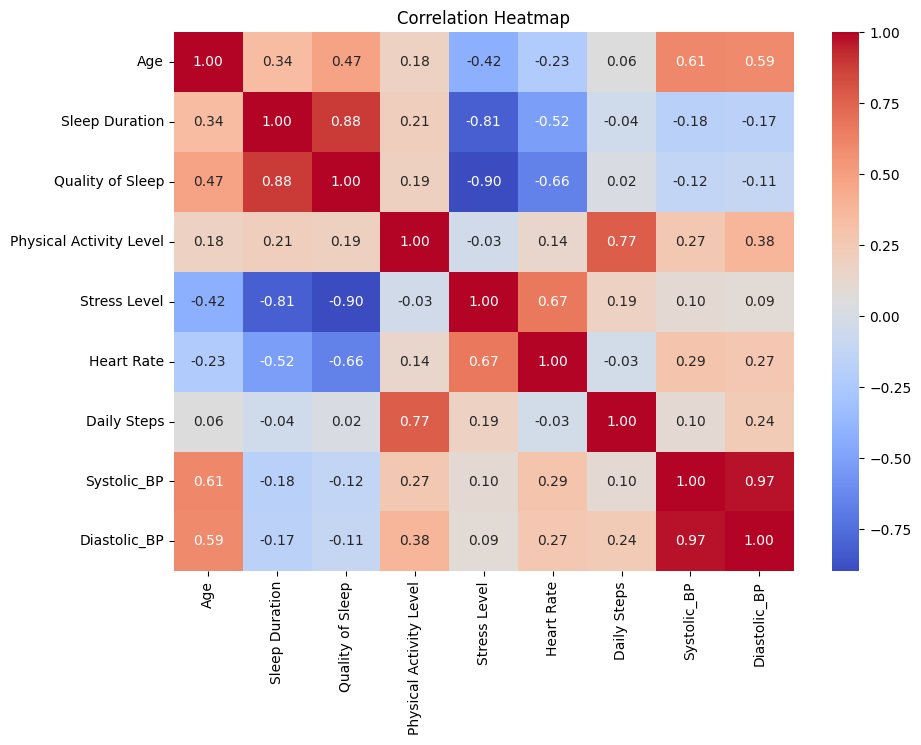

In [ ]:
# Correlation heatmap for numeric variables
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
corr = df_clean[numeric_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# 5. K-Means clustering

In [ ]:
# Prepare features for clustering

features = df_clean[["Sleep Duration", "Stress Level", "Physical Activity Level"]].copy()

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

scaled_df = pd.DataFrame(
    scaled_features,
    columns=features.columns,
    index=df_clean.index
)

scaled_df.head()

,Sleep Duration,Stress Level,Physical Activity Level
0,-1.298887,0.347021,-0.825418
1,-1.173036,1.475592,0.039844
2,-1.173036,1.475592,0.039844
3,-1.550588,1.475592,-1.402260
4,-1.550588,1.475592,-1.402260


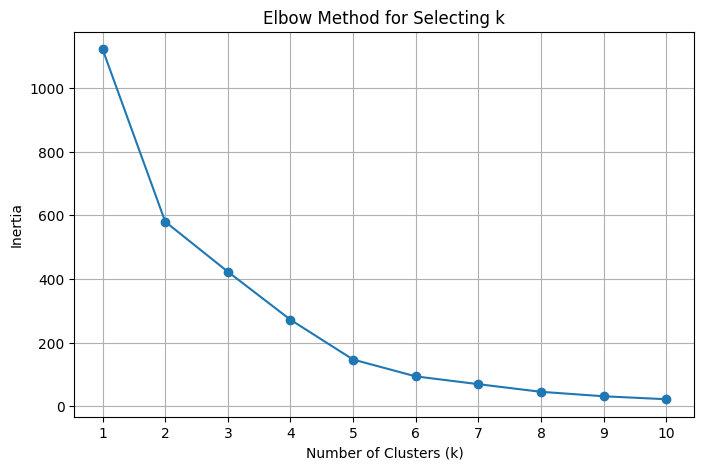

In [ ]:
# Choose k using the elbow method
inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Selecting k")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [ ]:
# Evaluate cluster quality with silhouette score

silhouette_scores = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = model.fit_predict(scaled_features)
    score = silhouette_score(scaled_features, cluster_labels)
    silhouette_scores.append((k, score))

print("Silhouette scores by k:")
for k, score in silhouette_scores:
    print(f"k={k}, silhouette_score={score:.4f}")

Silhouette scores by k:
k=2, silhouette_score=0.4756
k=3, silhouette_score=0.4370
k=4, silhouette_score=0.5636
k=5, silhouette_score=0.6120
k=6, silhouette_score=0.6731
k=7, silhouette_score=0.6793
k=8, silhouette_score=0.7160
k=9, silhouette_score=0.7549
k=10, silhouette_score=0.7784


In [ ]:
# Fit final K-Means model
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
df_clean["Cluster"] = kmeans.fit_predict(scaled_features)

df_clean[["Sleep Duration", "Stress Level", "Physical Activity Level", "Cluster"]].head()

,Sleep Duration,Stress Level,Physical Activity Level,Cluster
0,6.1,6,42,2
1,6.2,8,60,2
2,6.2,8,60,2
3,5.9,8,30,2
4,5.9,8,30,2


In [ ]:
# Verify the number of clusters in the final model
print("Number of clusters selected:", k)
print("Cluster labels:", sorted(df_clean["Cluster"].unique()))
print("Number of clusters found:", df_clean["Cluster"].nunique())

print("\nNumber of records in each cluster:")
print(df_clean["Cluster"].value_counts().sort_index())

Number of clusters selected: 5
Cluster labels: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4)]
Number of clusters found: 5

Number of records in each cluster:
Cluster
0    108
1     32
2     94
3     32
4    108
Name: count, dtype: int64


In [ ]:
# Summarize each cluster
cluster_summary = (
    df_clean.groupby("Cluster")[["Sleep Duration", "Stress Level", "Physical Activity Level", "Age", "Heart Rate", "Daily Steps"]]
    .mean()
    .round(2)
)

print(cluster_summary)

         Sleep Duration  Stress Level  Physical Activity Level    Age  \
Cluster                                                                 
0                  7.06          4.44                    55.60  39.22   
1                  6.07          8.00                    90.00  49.75   
2                  6.29          7.34                    38.72  37.70   
3                  8.43          3.00                    30.00  52.78   
4                  7.87          4.56                    80.05  43.67   

         Heart Rate  Daily Steps  
Cluster                           
0             68.21      6718.52  
1             75.00     10000.00  
2             73.28      5605.32  
3             65.00      5000.00  
4             69.51      7564.81  


**Selecting the Number of Clusters**

I compared 4, 5, 6, and 10 clusters using cluster sizes, feature averages, the elbow method, and silhouette scores. Four clusters grouped too many individuals together, while six and ten clusters introduced more detail and complexity.

I selected five clusters as a practical balance supporting comparisons of sleep duration, stress, and physical activity. These clusters represent exploratory lifestyle patterns, not definitive or clinical categories.

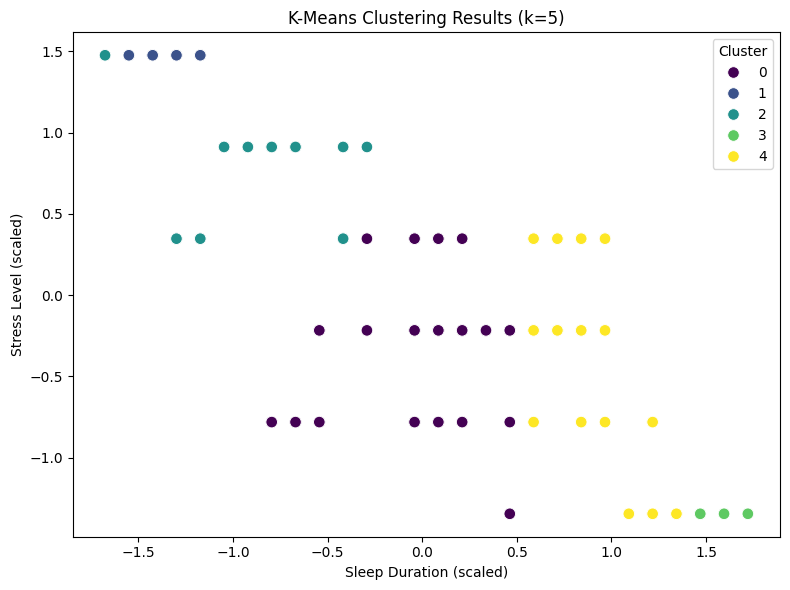

In [ ]:
# Visualize the final clusters
cluster_plot = scaled_df.copy()
cluster_plot["Cluster"] = df_clean["Cluster"]

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=cluster_plot,
    x="Sleep Duration",
    y="Stress Level",
    hue="Cluster",
    palette="viridis",
    s=70
)

plt.title(f"K-Means Clustering Results (k={k})")
plt.xlabel("Sleep Duration (scaled)")
plt.ylabel("Stress Level (scaled)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [ ]:
# Compare recorded sleep disorders across clusters

disorder_counts = pd.crosstab(
    df_clean["Cluster"],
    df_clean["Sleep Disorder"]
)

print(disorder_counts)

Sleep Disorder  Insomnia  No Disorder  Sleep Apnea
Cluster                                           
0                     27           77            4
1                      1            2           29
2                     45           38           11
3                      1           31            0
4                      3           71           34


# 6. Cluster Interpretation

### Cluster Interpretation

- **Cluster 0: Moderate stress and activity.** Average sleep was 7.06 hours, with moderate stress and activity. Most individuals had no recorded sleep disorder.
- **Cluster 1: High stress and activity.** This group had the shortest sleep duration (6.07 hours) and highest stress score (8.00). Sleep apnea was recorded for 29 of 32 individuals.
- **Cluster 2: High stress and lower activity.** Average sleep was 6.29 hours. Insomnia was the most common recorded disorder, affecting 45 of 94 individuals.
- **Cluster 3: Longer sleep and low stress.** This group had the longest average sleep (8.43 hours) and lowest stress score (3.00). Most individuals had no recorded sleep disorder.
- **Cluster 4: Longer sleep and higher activity.** Average sleep was 7.87 hours, and most individuals had no recorded disorder. However, 34 of 108 had sleep apnea.

Overall, the clusters revealed different combinations of sleep duration, stress, activity, and recorded sleep disorders. These are observed patterns, not evidence of cause and effect.

# 7. Key Findings and Limitations

### Key Findings

1. **Stress and sleep:** The higher-stress clusters had shorter average sleep durations.
2. **Physical activity:** Higher activity did not necessarily correspond to fewer recorded sleep disorders.
3. **Sleep disorders:** Sleep apnea was most common in Cluster 1, while insomnia was most prominent in Cluster 2.
4. **Clustering:** K-Means identified five groups with different lifestyle and sleep characteristics.

### Limitations

- The analysis identifies associations, not causal relationships.
- Clustering used only sleep duration, stress level, and physical activity level.
- Five clusters were selected for interpretation, although higher silhouette scores occurred at larger cluster numbers.
- Results depend on the quality and completeness of the supplied dataset.

Further analysis could examine age, BMI, occupation, and blood pressure to explore additional patterns.

# 8. Conclusion and Reflection

**Conclusion**

This project explored sleep and lifestyle patterns among 374 individuals using exploratory data analysis and K-Means clustering. The five clusters showed differences in sleep duration, stress, physical activity, and recorded sleep disorders.

The findings highlight how data analytics can identify patterns and support further investigation, but they do not establish cause and effect. Overall, the project strengthened my skills in data preparation, analysis, visualization, and evidence-based interpretation.


**Reflection**

This project strengthened my practical skills in Python, data cleaning, exploratory data analysis, visualization, and K-Means clustering. I learned the importance of checking data quality, validating model outputs, and ensuring that written interpretations match the results.

The analysis showed me how data can reveal patterns that require further investigation. I also learned to interpret findings cautiously and avoid assuming that associations imply causation.

In future projects, I would compare alternative clustering solutions and explore additional variables to deepen my analysis.